<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/%20Information%20Extraction%20(IE)%20from%20structured/unstructured%20documents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.

STRUCTURED DOCUMENT INFORMATION

        Name           Email      Phone             Department     Organization
Rahul Sharma rahul@gmail.com 9876543210       Computer Science ABC Technologies
 Priya Verma priya@yahoo.com 8765432109 Information Technology    XYZ Solutions
  Amit Singh  amit@gmail.com 7654321098            Electronics       Tech India

UNSTRUCTURED DOCUMENT INFORMATION EXTRACTION

     Persons Organizations Locations                       Dates                    Emails Phone Numbers  Document ID
Rahul Sharma        Google New Delhi 9876543210, 15 January 2024    rahul.sharma@gmail.com    9876543210            1
 Priya Verma     Microsoft 

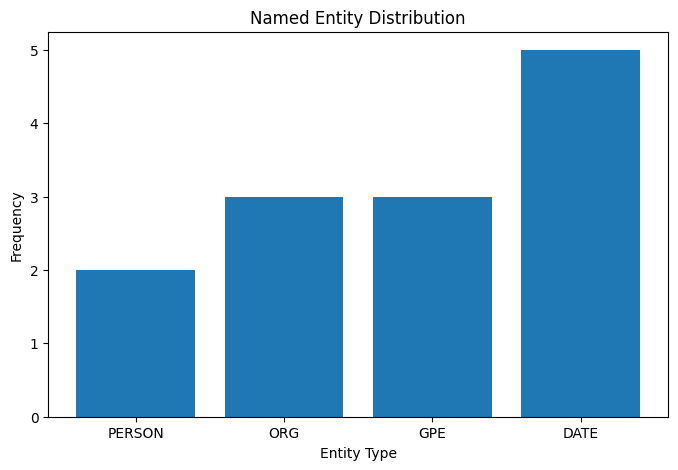


CONTACT INFORMATION

Document 1
Email: rahul.sharma@gmail.com
Phone: 9876543210

Document 2
Email: priya.verma@microsoft.com
Phone: 8765432109

Document 3
Email: amit.singh@amazon.com
Phone: 7654321098

CUSTOM DOCUMENT INFORMATION EXTRACTION

Persons: Not found
Organizations: Hyderabad, Infosys, Ankit Kumar
Locations: Not found
Dates: 12 August 2025, 9876543210
Emails: ankit.kumar@infosys.com
Phone Numbers: 9876543210

Information Extraction Completed Successfully!


In [8]:

# Information Extraction (IE) from Structured/Unstructured Documents

!pip install -q spacy pandas matplotlib
!python -m spacy download en_core_web_sm -q

import re
import spacy
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

# Load NLP model
nlp = spacy.load("en_core_web_sm")

# Structured document dataset
structured_data = {
    'Name': ['Rahul Sharma', 'Priya Verma', 'Amit Singh'],
    'Email': ['rahul@gmail.com', 'priya@yahoo.com', 'amit@gmail.com'],
    'Phone': ['9876543210', '8765432109', '7654321098'],
    'Department': ['Computer Science', 'Information Technology', 'Electronics'],
    'Organization': ['ABC Technologies', 'XYZ Solutions', 'Tech India']
}

structured_df = pd.DataFrame(structured_data)

# Unstructured document dataset
documents = [
    """
    Rahul Sharma works at Google in New Delhi.
    He joined the organization on 15 January 2024.
    His email is rahul.sharma@gmail.com and contact number is 9876543210.
    """,
    """
    Priya Verma is employed at Microsoft in Bengaluru.
    She started working on 20 March 2023.
    Her email address is priya.verma@microsoft.com.
    Contact number: 8765432109.
    """,
    """
    Amit Singh works for Amazon in Mumbai.
    He joined on 10 July 2022.
    His email is amit.singh@amazon.com.
    Phone: 7654321098.
    """
]

# Information extraction function
def extract_information(text):
    doc = nlp(text)

    # Named Entity Recognition
    entities = {
        'PERSON': [],
        'ORG': [],
        'GPE': [],
        'DATE': []
    }

    for ent in doc.ents:
        if ent.label_ in entities:
            entities[ent.label_].append(ent.text)

    # Extract email addresses
    emails = re.findall(
        r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}',
        text
    )

    # Extract phone numbers
    phones = re.findall(
        r'(?<!\d)(?:\+91[-\s]?)?[6-9]\d{9}(?!\d)',
        text
    )

    return {
        'Persons': ', '.join(set(entities['PERSON'])) or 'Not found',
        'Organizations': ', '.join(set(entities['ORG'])) or 'Not found',
        'Locations': ', '.join(set(entities['GPE'])) or 'Not found',
        'Dates': ', '.join(set(entities['DATE'])) or 'Not found',
        'Emails': ', '.join(set(emails)) or 'Not found',
        'Phone Numbers': ', '.join(set(phones)) or 'Not found'
    }

# Extract information from unstructured documents
extracted_results = []

for index, document in enumerate(documents):
    result = extract_information(document)
    result['Document ID'] = index + 1
    extracted_results.append(result)

unstructured_df = pd.DataFrame(extracted_results)

# Display structured information
print("\nSTRUCTURED DOCUMENT INFORMATION\n")
print(structured_df.to_string(index=False))

# Display unstructured information
print("\nUNSTRUCTURED DOCUMENT INFORMATION EXTRACTION\n")
print(unstructured_df.to_string(index=False))

# Extract all entities for analysis
entity_counts = Counter()

for document in documents:
    doc = nlp(document)
    for ent in doc.ents:
        if ent.label_ in ['PERSON', 'ORG', 'GPE', 'DATE']:
            entity_counts[ent.label_] += 1

# Entity distribution visualization
plt.figure(figsize=(8, 5))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.title("Named Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.show()

# Display extracted email and phone information
print("\nCONTACT INFORMATION")

for i, result in enumerate(extracted_results):
    print(f"\nDocument {i+1}")
    print("Email:", result['Emails'])
    print("Phone:", result['Phone Numbers'])

# Custom document extraction
custom_text = """
Ankit Kumar joined Infosys in Hyderabad on 12 August 2025.
His email is ankit.kumar@infosys.com and phone number is 9876543210.
"""

print("\nCUSTOM DOCUMENT INFORMATION EXTRACTION\n")

custom_result = extract_information(custom_text)

for key, value in custom_result.items():
    print(f"{key}: {value}")

print("\nInformation Extraction Completed Successfully!")
